# El problema del vaso lleno de café · Notebook 01
## KPIs de merma, Pareto 80/20 y escenarios hacia la meta del 15 %

> ⚠️ **Los datos de este notebook son SIMULADOS.** Sirven solo para probar que el pipeline funciona.
> Ninguna conclusión de negocio se saca de acá hasta reemplazarlos por la medición de línea base real
> (`data/plantilla_registro_mermas.csv`).

In [1]:
# --- Celda 1: configuración ---
# Justificación: centralizar parámetros evita "números mágicos" repartidos por el notebook
# y deja claro qué es SUPUESTO y qué vendrá del relevamiento.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEMILLA = 42                     # reproducibilidad: cualquiera que corra el notebook obtiene lo mismo
USAR_DATOS_SIMULADOS = True      # pasar a False cuando haya datos reales
# Justificación: dentro del repo el notebook vive en notebooks/ y los datos en ../data;
# en Google Colab no existe esa estructura, así que se usa ./data y se crea si falta.
RUTA_DATOS = Path('../data') if Path('../data').is_dir() else Path('data')
RUTA_DATOS.mkdir(parents=True, exist_ok=True)

# Receta estándar [SUPUESTO] -> se reemplaza por la receta real del local
DOSIS_ESPRESSO_G = 18.0          # doble espresso, base de la mayoría de las bebidas con leche
DOSIS_FILTRADO_G = 15.0          # 15 g para ~250 ml (ratio 1:16-1:17)

PRECIO_KG_ARS = 40_000           # [SUPUESTO] café de especialidad, rango minorista observado 2026: ~34.000-71.000 ARS/kg
META_TASA_MERMA = 0.15           # objetivo específico 2 del proyecto
DIAS = 30

In [2]:
# --- Celda 2: generación de datos SIMULADOS ---
# Justificación: se simulan las 8 causas de merma identificadas en el árbol de problemas (doc 02),
# con medias diarias plausibles, para probar el cálculo de KPIs y el Pareto antes de ir a campo.
rng = np.random.default_rng(SEMILLA)

# media diaria en gramos por causa [SIMULADO] y si la causa es evitable
causas = {
    'Café pre-molido sobrante':            (600, True),
    'Lote de filtrado sobrante':           (250, True),
    'Sobredosis (dosis > receta)':         (120, True),
    'Shots de calibración (dial-in)':      (70,  False),
    'Purgas (inicio y ajustes)':           (60,  False),
    'Shots descartados / rehechos':        (50,  True),
    'Derrames en dosificado y tampeo':     (30,  True),
    'Retención del molino al cierre':      (20,  False),
}

fechas = pd.date_range('2026-11-01', periods=DIAS, freq='D')
filas_merma, filas_ventas = [], []
for f in fechas:
    factor_dia = 1.25 if f.dayofweek >= 5 else 1.0          # fines de semana con más movimiento
    for turno, peso_turno in [('mañana', 0.55), ('tarde', 0.45)]:
        esp = rng.poisson(180 * factor_dia * peso_turno)
        fil = rng.poisson(40 * factor_dia * peso_turno)
        filas_ventas.append({'fecha': f, 'turno': turno, 'bebidas_espresso': esp, 'bebidas_filtrado': fil})
        for causa, (media, evitable) in causas.items():
            g = max(0, rng.normal(media * factor_dia * peso_turno, media * 0.25 * peso_turno))
            filas_merma.append({'fecha': f, 'turno': turno, 'causa': causa,
                                'evitable': evitable, 'gramos': round(g, 1)})

mermas = pd.DataFrame(filas_merma)
ventas = pd.DataFrame(filas_ventas)

if USAR_DATOS_SIMULADOS:
    mermas.to_csv(RUTA_DATOS / 'mermas_SIMULADO.csv', index=False)
    ventas.to_csv(RUTA_DATOS / 'ventas_SIMULADO.csv', index=False)
mermas.head()

,fecha,turno,causa,evitable,gramos
0,2026-11-01,mañana,Café pre-molido sobrante,True,251.5
1,2026-11-01,mañana,Lote de filtrado sobrante,True,127.1
2,2026-11-01,mañana,Sobredosis (dosis > receta),True,84.6
3,2026-11-01,mañana,Shots de calibración (dial-in),False,45.1
4,2026-11-01,mañana,Purgas (inicio y ajustes),False,41.1


In [3]:
# --- Celda 3: KPIs principales ---
# Justificación: la tasa de merma se define sobre el café EGRESADO del stock (teórico vendido + merma),
# que es exactamente lo que el dueño ve "desaparecer" a fin de mes al cerrar caja.
ventas['cafe_teorico_g'] = ventas.bebidas_espresso * DOSIS_ESPRESSO_G + ventas.bebidas_filtrado * DOSIS_FILTRADO_G
merma_turno = mermas.groupby(['fecha', 'turno'], as_index=False).gramos.sum().rename(columns={'gramos': 'merma_g'})
kpi = ventas.merge(merma_turno, on=['fecha', 'turno'])
kpi['egresado_g'] = kpi.cafe_teorico_g + kpi.merma_g
kpi['bebidas'] = kpi.bebidas_espresso + kpi.bebidas_filtrado

tasa = kpi.merma_g.sum() / kpi.egresado_g.sum()
g_por_taza_real = kpi.egresado_g.sum() / kpi.bebidas.sum()
g_por_taza_teo = kpi.cafe_teorico_g.sum() / kpi.bebidas.sum()
merma_kg_mes = kpi.merma_g.sum() / 1000

print(f'Tasa de merma (mes)          : {tasa:.1%}')
print(f'Gramos por taza (receta)     : {g_por_taza_teo:.1f} g')
print(f'Gramos por taza (real)       : {g_por_taza_real:.1f} g')
print(f'Café perdido en el mes       : {merma_kg_mes:.1f} kg')
print(f'Costo de la merma (mes)      : ${merma_kg_mes * PRECIO_KG_ARS:,.0f} ARS')
print(f'Tazas que se podrían servir  : {kpi.merma_g.sum() / g_por_taza_teo:,.0f}')

Tasa de merma (mes)          : 23.9%
Gramos por taza (receta)     : 17.5 g
Gramos por taza (real)       : 22.9 g
Café perdido en el mes       : 38.4 kg
Costo de la merma (mes)      : $1,536,172 ARS
Tazas que se podrían servir  : 2,200


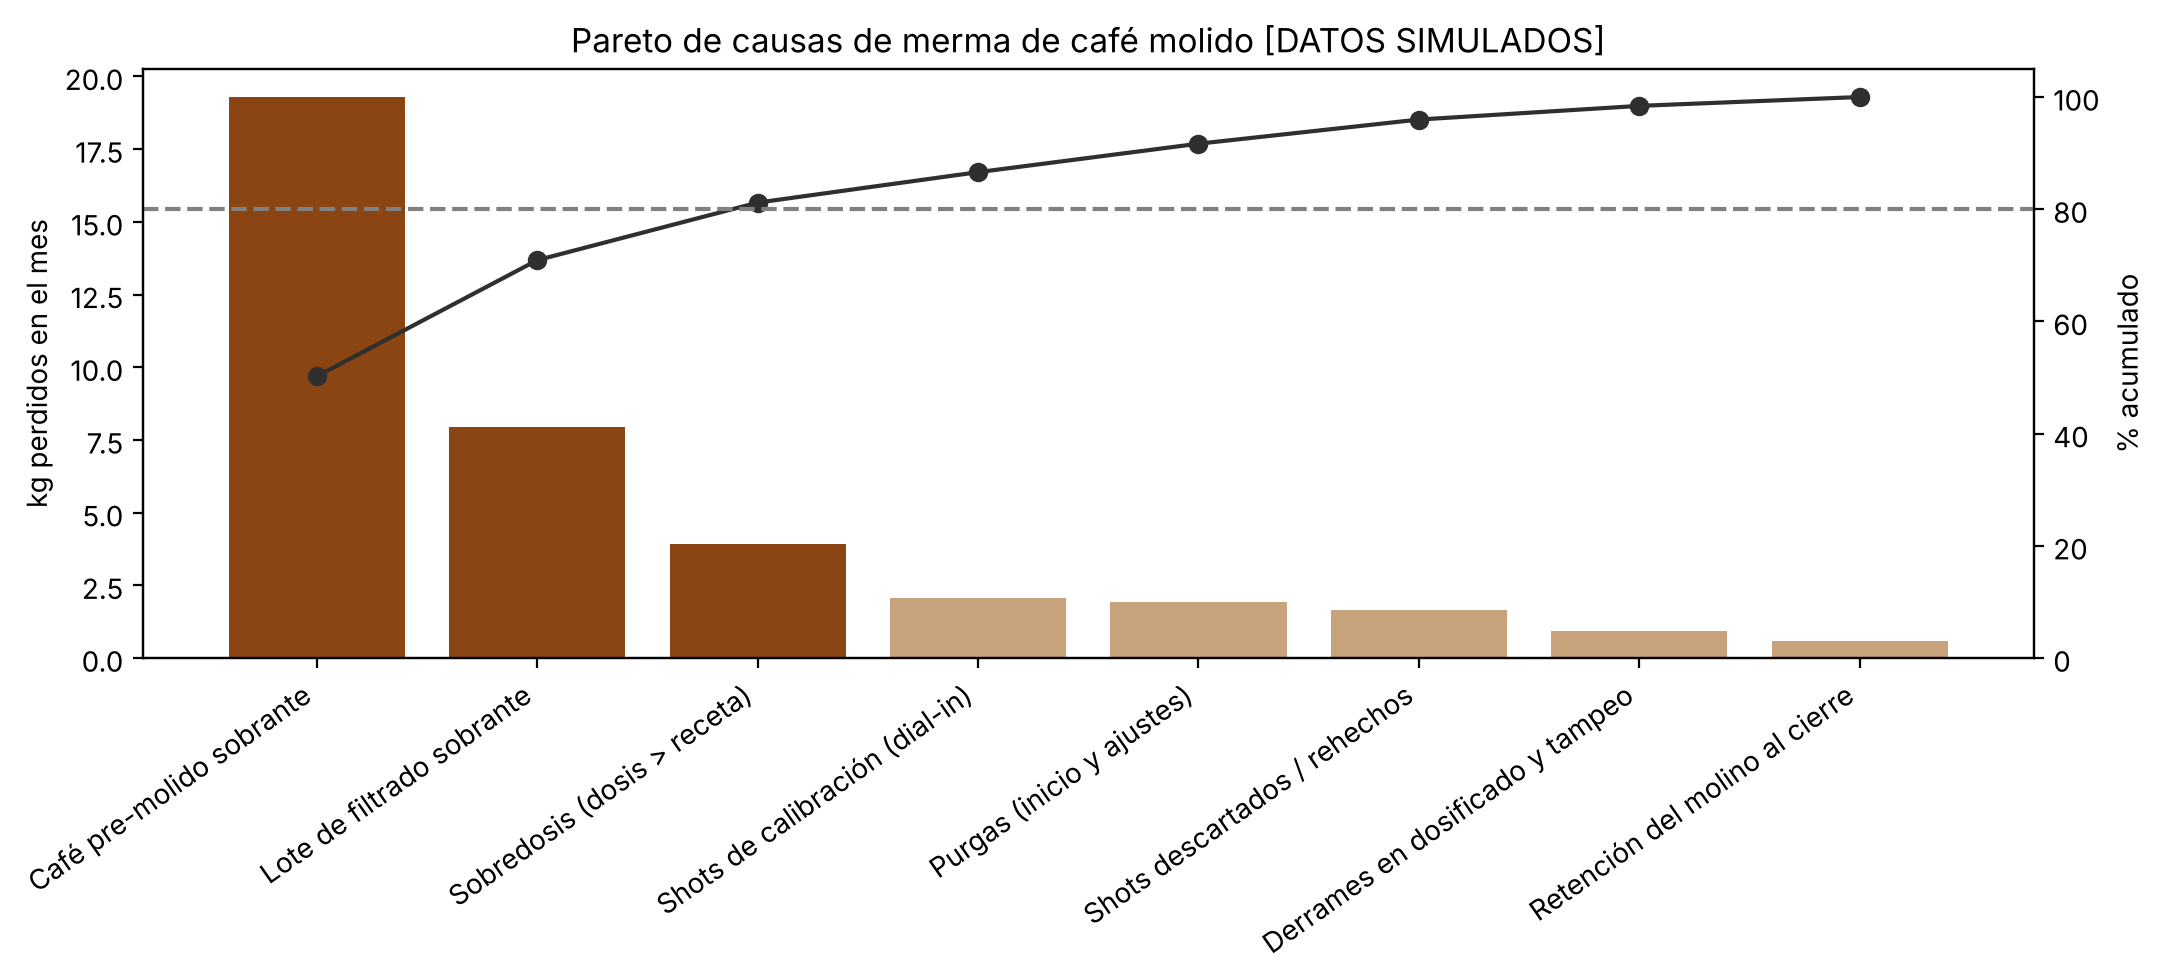

,causa,evitable,gramos,pct,pct_acum,zona
0,Café pre-molido sobrante,True,19293.5,0.502,0.502,A (vital)
2,Lote de filtrado sobrante,True,7945.9,0.207,0.709,A (vital)
7,Sobredosis (dosis > receta),True,3938.8,0.103,0.812,A (vital)
5,Shots de calibración (dial-in),False,2084.2,0.054,0.866,B (trivial)
3,Purgas (inicio y ajustes),False,1946.2,0.051,0.917,B (trivial)
6,Shots descartados / rehechos,True,1653.2,0.043,0.960,B (trivial)
1,Derrames en dosificado y tampeo,True,935.7,0.024,0.984,B (trivial)
4,Retención del molino al cierre,False,606.8,0.016,1.000,B (trivial)


In [4]:
# --- Celda 4: Pareto 80/20 por causa ---
# Justificación: el Pareto ordena las causas por gramos perdidos y muestra el acumulado;
# las causas a la izquierda del corte del 80 % son las que se priorizan en la solución.
par = mermas.groupby(['causa', 'evitable'], as_index=False).gramos.sum().sort_values('gramos', ascending=False)
par['pct'] = par.gramos / par.gramos.sum()
par['pct_acum'] = par.pct.cumsum()
par['zona'] = np.where(par.pct_acum.shift(fill_value=0) < 0.80, 'A (vital)', 'B (trivial)')

fig, ax = plt.subplots(figsize=(11, 5))
colores = ['#8B4513' if z.startswith('A') else '#C8A27A' for z in par.zona]
ax.bar(par.causa, par.gramos / 1000, color=colores)
ax.set_ylabel('kg perdidos en el mes')
ax.tick_params(axis='x', rotation=35)
plt.setp(ax.get_xticklabels(), ha='right')
ax2 = ax.twinx()
ax2.plot(par.causa, par.pct_acum * 100, color='#2F2F2F', marker='o')
ax2.axhline(80, ls='--', color='grey')
ax2.set_ylim(0, 105); ax2.set_ylabel('% acumulado')
ax.set_title('Pareto de causas de merma de café molido [DATOS SIMULADOS]')
plt.tight_layout(); plt.show()
par[['causa', 'evitable', 'gramos', 'pct', 'pct_acum', 'zona']].round(3)

In [5]:
# --- Celda 5: evitable vs. inevitable ---
# Justificación: separa lo que se puede PREVENIR (objetivo 2) de lo que solo se puede VALORIZAR (objetivo 1).
ev = mermas.groupby('evitable').gramos.sum()
print(f"Merma evitable  : {ev.get(True, 0) / ev.sum():.1%}")
print(f"Merma inevitable: {ev.get(False, 0) / ev.sum():.1%}")

Merma evitable  : 87.9%
Merma inevitable: 12.1%


In [6]:
# --- Celda 6: escenarios de reducción ---
# Justificación: estima si la meta del 15 % es alcanzable atacando solo la zona A del Pareto.
# Los % de reducción por intervención son [SUPUESTOS] a validar en el piloto.
reduccion = {
    'Café pre-molido sobrante':        0.80,  # molienda a demanda
    'Lote de filtrado sobrante':       0.50,  # lote según pronóstico por franja
    'Sobredosis (dosis > receta)':     0.70,  # dosificar con balanza
    'Shots descartados / rehechos':    0.30,  # capacitación + protocolo
    'Derrames en dosificado y tampeo': 0.30,
}
esc = par[['causa', 'gramos']].copy()
esc['reduccion'] = esc.causa.map(reduccion).fillna(0)
esc['gramos_post'] = esc.gramos * (1 - esc.reduccion)

teorico_total = kpi.cafe_teorico_g.sum()
tasa_post = esc.gramos_post.sum() / (teorico_total + esc.gramos_post.sum())
ahorro_kg = (esc.gramos.sum() - esc.gramos_post.sum()) / 1000
print(f'Tasa de merma actual   : {tasa:.1%}')
print(f'Tasa de merma escenario: {tasa_post:.1%}   (meta: {META_TASA_MERMA:.0%})')
print(f'Ahorro estimado        : {ahorro_kg:.1f} kg/mes = ${ahorro_kg * PRECIO_KG_ARS:,.0f} ARS/mes')
print(f'Residuo que queda para valorizar (obj. 1): {esc.gramos_post.sum()/1000:.1f} kg/mes')

Tasa de merma actual   : 23.9%
Tasa de merma escenario: 11.2%   (meta: 15%)
Ahorro estimado        : 22.9 kg/mes = $917,663 ARS/mes
Residuo que queda para valorizar (obj. 1): 15.5 kg/mes


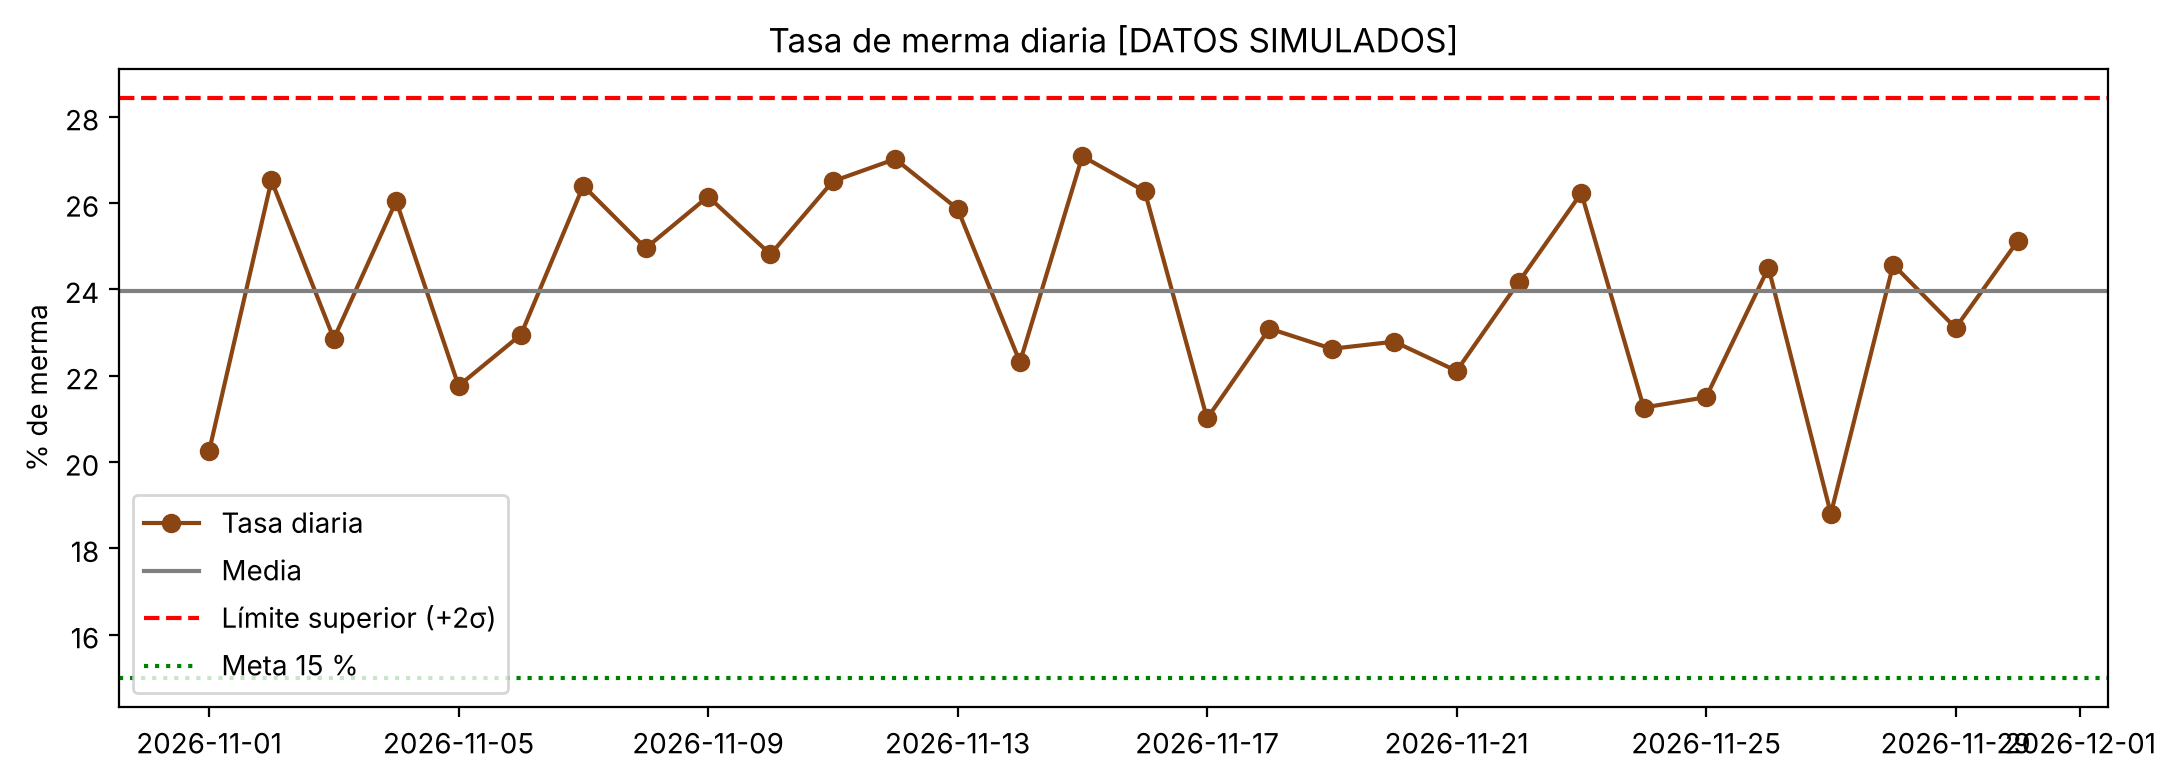

,merma_g,egresado_g,tasa
fecha,,,


In [7]:
# --- Celda 7: evolución diaria y control estadístico ---
# Justificación: una carta de control (media ± 2 desvíos) detecta días anómalos que conviene
# investigar con el equipo (base para el futuro módulo de detección de anomalías).
diario = kpi.groupby('fecha').agg(merma_g=('merma_g', 'sum'), egresado_g=('egresado_g', 'sum'))
diario['tasa'] = diario.merma_g / diario.egresado_g
m, s = diario.tasa.mean(), diario.tasa.std()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diario.index, diario.tasa * 100, marker='o', color='#8B4513', label='Tasa diaria')
ax.axhline(m * 100, color='grey', label='Media')
ax.axhline((m + 2*s) * 100, ls='--', color='red', label='Límite superior (+2σ)')
ax.axhline(META_TASA_MERMA * 100, ls=':', color='green', label='Meta 15 %')
ax.set_ylabel('% de merma'); ax.legend(); ax.set_title('Tasa de merma diaria [DATOS SIMULADOS]')
plt.tight_layout(); plt.show()
diario[diario.tasa > m + 2*s]

## Próximos pasos
1. Reemplazar los datos simulados por **2-4 semanas de registro real** (línea base).
2. Rehacer el Pareto: si la zona A cambia, **cambia la prioridad de la solución**.
3. Recalibrar los % de reducción de la celda 6 con lo observado en el piloto.